# Part 1A — NYC Airbnb: EDA, preprocessing, clustering, anomaly removal and AutoViML
Download [NYC Airbnb Open Data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data), upload `AB_NYC_2019.csv` to the Colab Files sidebar, then run cells from top to bottom. AutoViML may need additional installation or a compatible environment. Results are not pre-executed.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

# Automatically download the NYC Airbnb dataset
DATA = Path("/content/AB_NYC_2019.csv")

url = (
    "https://huggingface.co/datasets/"
    "gradio/NYC-Airbnb-Open-Data/"
    "resolve/main/AB_NYC_2019.csv"
)

if not DATA.exists():
    import requests

    response = requests.get(url, timeout=60)
    response.raise_for_status()
    DATA.write_bytes(response.content)

# Load the dataset
raw = pd.read_csv(DATA)

print("Dataset shape:", raw.shape)
display(raw.head())
raw.info()


Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

## 1. Raw EDA — inspect before cleaning

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,48895.0,NaN,NaN,NaN,19017143.23618,10983108.38561,2539.0,9471945.0,19677284.0,29152178.5,36487245.0
name,48879,47905,Hillside Hotel,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,48895.0,NaN,NaN,NaN,67620010.64661,78610967.032667,2438.0,7822033.0,30793816.0,107434423.0,274321313.0
host_name,48874,11452,Michael,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_group,48895,5,Manhattan,21661,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood,48895,221,Williamsburg,3920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,48895.0,NaN,NaN,NaN,40.728949,0.05453,40.49979,40.6901,40.72307,40.763115,40.91306
longitude,48895.0,NaN,NaN,NaN,-73.95217,0.046157,-74.24442,-73.98307,-73.95568,-73.936275,-73.71299
room_type,48895,3,Entire home/apt,25409,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,48895.0,NaN,NaN,NaN,152.720687,240.15417,0.0,69.0,106.0,175.0,10000.0


,dtype,missing,pct_missing,unique
id,int64,0,0.000000,48895
name,object,16,0.032723,47906
host_id,int64,0,0.000000,37457
host_name,object,21,0.042949,11453
neighbourhood_group,object,0,0.000000,5
neighbourhood,object,0,0.000000,221
latitude,float64,0,0.000000,19048
longitude,float64,0,0.000000,14718
room_type,object,0,0.000000,3
price,int64,0,0.000000,674


Exact duplicates: 0 Duplicate listing IDs: 0


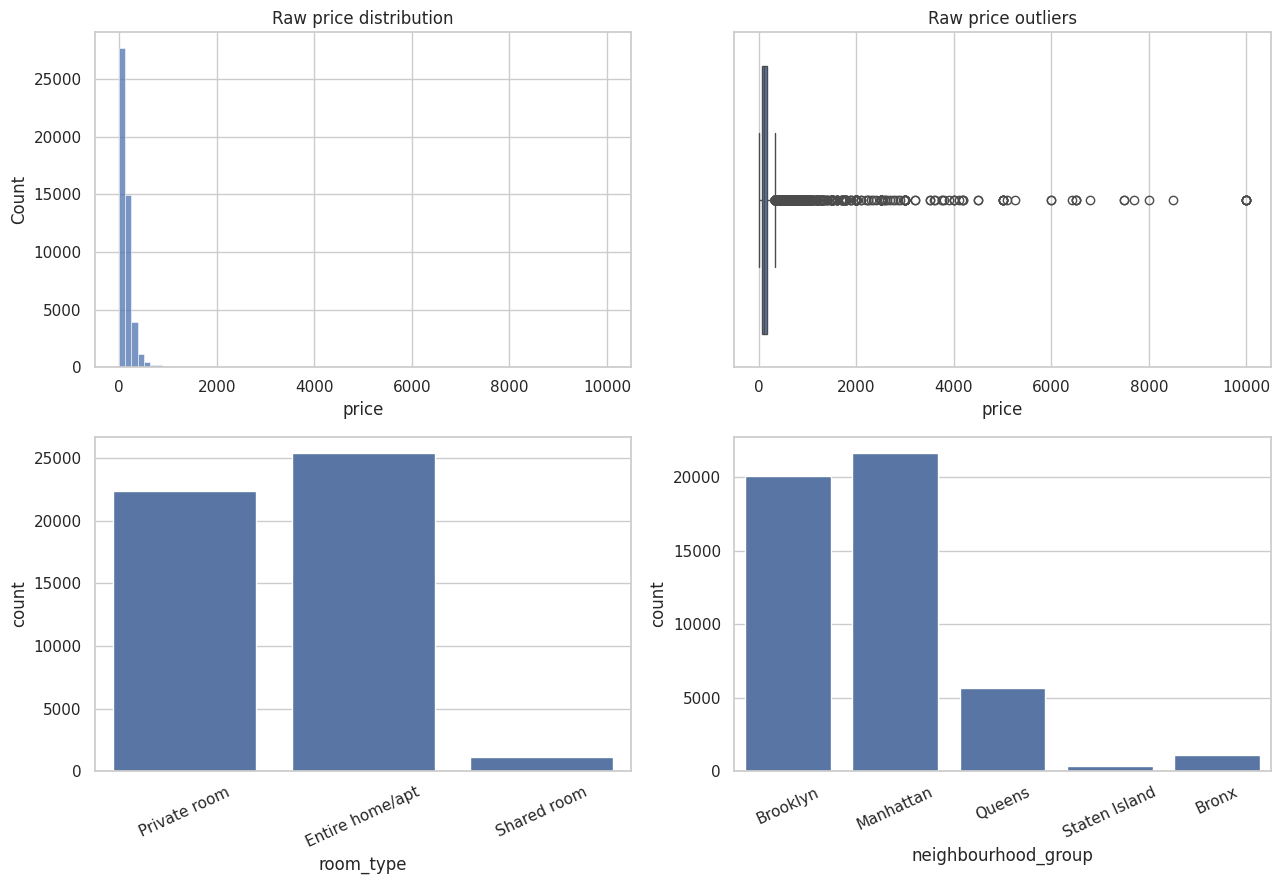

,count,median,mean
neighbourhood_group,,,
Manhattan,21661,150.0,196.875814
Brooklyn,20104,90.0,124.383207
Queens,5666,75.0,99.517649
Staten Island,373,75.0,114.812332
Bronx,1091,65.0,87.496792


In [ ]:
display(raw.describe(include='all').T)
display(pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum(),'pct_missing':100*raw.isna().mean(),'unique':raw.nunique(dropna=False)}))
print('Exact duplicates:', raw.duplicated().sum(), 'Duplicate listing IDs:',raw['id'].duplicated().sum())
fig,axs=plt.subplots(2,2,figsize=(13,9))
sns.histplot(raw['price'],bins=80,ax=axs[0,0]); axs[0,0].set_title('Raw price distribution')
sns.boxplot(x=raw['price'],ax=axs[0,1]); axs[0,1].set_title('Raw price outliers')
sns.countplot(data=raw,x='room_type',ax=axs[1,0]); axs[1,0].tick_params(axis='x',rotation=25)
sns.countplot(data=raw,x='neighbourhood_group',ax=axs[1,1]); axs[1,1].tick_params(axis='x',rotation=25)
plt.tight_layout(); plt.show()
display(raw.groupby('neighbourhood_group')['price'].agg(['count','median','mean']).sort_values('median',ascending=False))

## 2. Cleaning, missingness and business rules

In [ ]:
df=raw.drop_duplicates(subset=['id']).copy()
# Reviews absent for listings with zero reviews should not mean fabricated reviews.
df['reviews_per_month']=df['reviews_per_month'].fillna(0)
df['last_review']=pd.to_datetime(df['last_review'],errors='coerce')
reference_date=pd.Timestamp('2019-07-09')
df['days_since_review']=(reference_date-df['last_review']).dt.days
# Do not leak IDs, names or text into the price regressor without explicit NLP or encoding.
df=df.drop(columns=['id','host_id','name','host_name','last_review'],errors='ignore')
for col in ['price','minimum_nights','availability_365','latitude','longitude']:
    df[col]=pd.to_numeric(df[col],errors='coerce')
df=df[df['price'].gt(0) & df['minimum_nights'].ge(1) & df['availability_365'].between(0,365) & df['latitude'].between(40,41) & df['longitude'].between(-75,-73)]
print('After business-rule filtering:',df.shape)
print('Remaining missing values:');display(df.isna().sum()[lambda s:s>0])

After business-rule filtering: (48884, 12)
Remaining missing values:


,0
days_since_review,10051


## 3. Train/test split BEFORE learned preprocessing

In [ ]:
train,test=train_test_split(df,test_size=.2,random_state=42)
# Price outlier threshold learned only on train. Avoid removing plausible expensive listings from evaluation.
lo,hi=train['price'].quantile([.01,.99]); train=train[train['price'].between(lo,hi)].copy()
print('Training price thresholds:',lo,hi,'train:',len(train),'test:',len(test))
# Impute from training data only.
num=[c for c in train.select_dtypes(include='number').columns if c!='price']
cat=[c for c in train.select_dtypes(exclude='number').columns]
imp=SimpleImputer(strategy='median');train[num]=imp.fit_transform(train[num]);test[num]=imp.transform(test[num])
for c in cat:
    fill=train[c].mode(dropna=True).iloc[0] if not train[c].mode(dropna=True).empty else 'Unknown'
    train[c]=train[c].fillna(fill);test[c]=test[c].fillna(fill)
# Other than training, nothing below is fitted on test.
print('Train',train.shape,'Test',test.shape)

Training price thresholds: 30.0 798.7600000000093 train: 38408 test: 9777
Train (38408, 12) Test (9777, 12)


## 4. Clustering and anomaly removal (training only)

Cluster sizes:


,count
cluster,
0,9522
1,8446
2,17572
3,105
4,2763


,price,minimum_nights,availability_365
cluster,,,
0,125.0,3.0,316.0
1,90.0,2.0,9.0
2,110.0,3.0,0.0
3,115.0,240.0,305.0
4,105.0,2.0,197.0


Training-only multivariate anomalies removed: 769


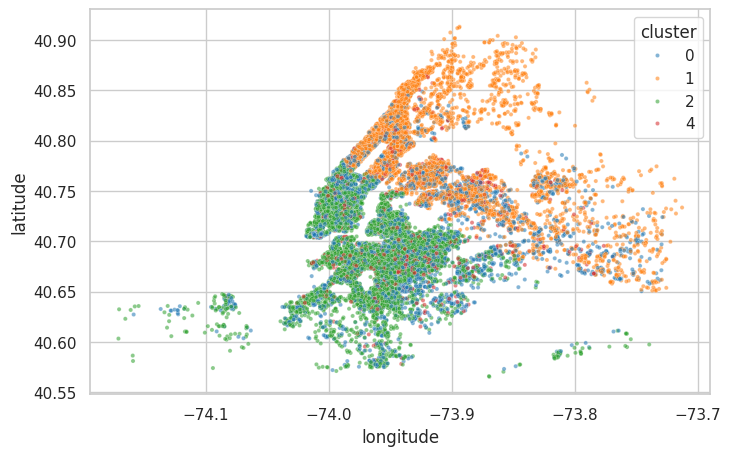

In [ ]:
cluster_cols=['latitude','longitude','minimum_nights','number_of_reviews','availability_365']
scale=StandardScaler(); z=scale.fit_transform(train[cluster_cols]); z_test=scale.transform(test[cluster_cols])
km=KMeans(n_clusters=5,random_state=42,n_init=10)
train['cluster']=km.fit_predict(z);test['cluster']=km.predict(z_test)
print('Cluster sizes:');display(train['cluster'].value_counts().sort_index())
display(train.groupby('cluster')[['price','minimum_nights','availability_365']].median())
anomaly=IsolationForest(contamination=.02,random_state=42)
flags=anomaly.fit_predict(z)
print('Training-only multivariate anomalies removed:',(flags==-1).sum())
train=train.loc[flags==1].copy()
fig,ax=plt.subplots(figsize=(8,5));sns.scatterplot(data=train,x='longitude',y='latitude',hue='cluster',palette='tab10',s=9,alpha=.55,ax=ax);plt.show()

## 5. Manual feature selection and baseline model

In [ ]:
# Explicit price is target. Remove identifier-like high-cardinality neighborhood labels from baseline only if desired.
Xtr=pd.get_dummies(train.drop(columns=['price']),dummy_na=False)
Xte=pd.get_dummies(test.drop(columns=['price']),dummy_na=False).reindex(columns=Xtr.columns,fill_value=0)
base=RandomForestRegressor(n_estimators=120,min_samples_leaf=3,random_state=42,n_jobs=-1)
base.fit(Xtr,train['price']);pred=base.predict(Xte)
print({'MAE':mean_absolute_error(test['price'],pred),'RMSE':float(np.sqrt(mean_squared_error(test['price'],pred))),'R2':r2_score(test['price'],pred)})
display(pd.Series(base.feature_importances_,index=Xtr.columns).sort_values(ascending=False).head(20))

{'MAE': 57.73471453430802, 'RMSE': 181.09634544908104, 'R2': 0.1808390453521017}


,0
room_type_Entire home/apt,0.314705
longitude,0.170314
latitude,0.126392
availability_365,0.088962
minimum_nights,0.056999
reviews_per_month,0.049236
number_of_reviews,0.045962
days_since_review,0.045033
calculated_host_listings_count,0.042504
neighbourhood_Midtown,0.022331


In [ ]:

%pip install autoviml


In [ ]:

from autoviml.Auto_ViML import Auto_ViML

print("AutoViML imported successfully!")


Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)
AutoViML imported successfully!


## 6. AutoViML — automated feature selection and model variants
AutoViML dependencies may require a separate compatible environment; see README. Compare returned model performance to the baseline on untouched test data. AutoViML may train several candidate variants internally.

Training rows: 5000
##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (5000, 13)
    Training Set Memory Usage = 0.51 MB
Test Set Shape = (9777, 12)
    Test Set Memory Usage = 0.93 MB
Single_Label Target: ['price']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    12 Predictors classified...
    No variables removed since no ID or low-information variables found in data set
##############################################################################
######     D A T A    P R E P 

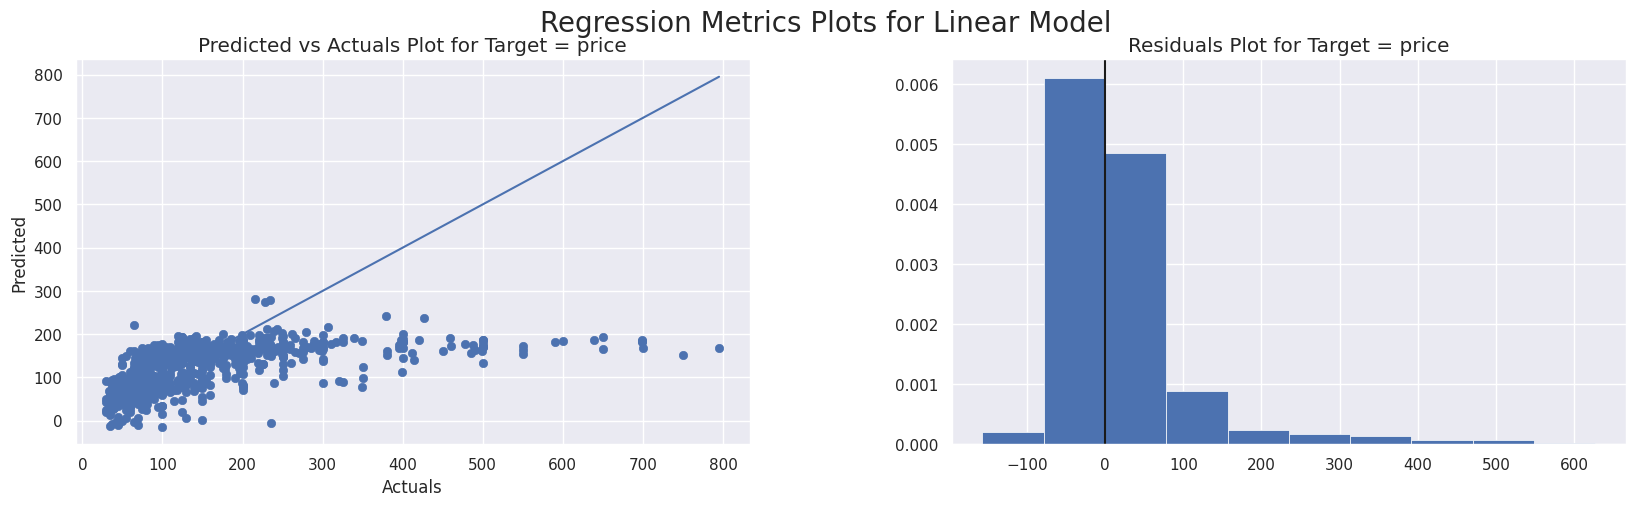

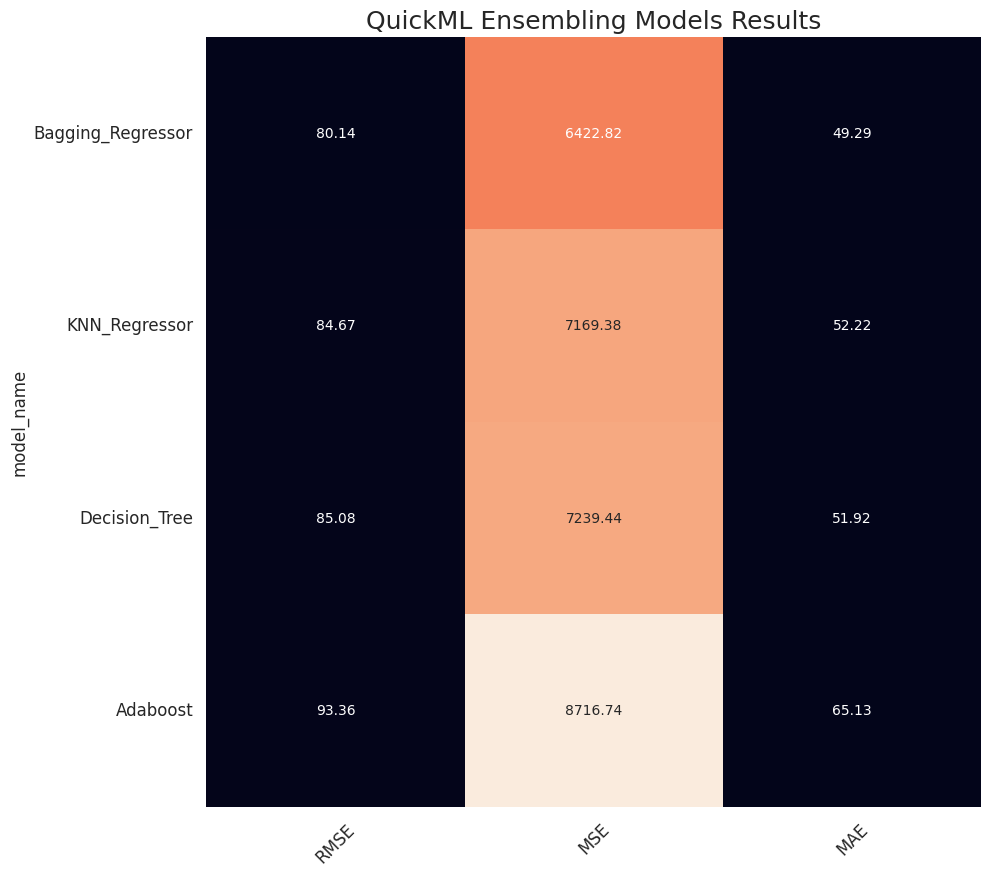

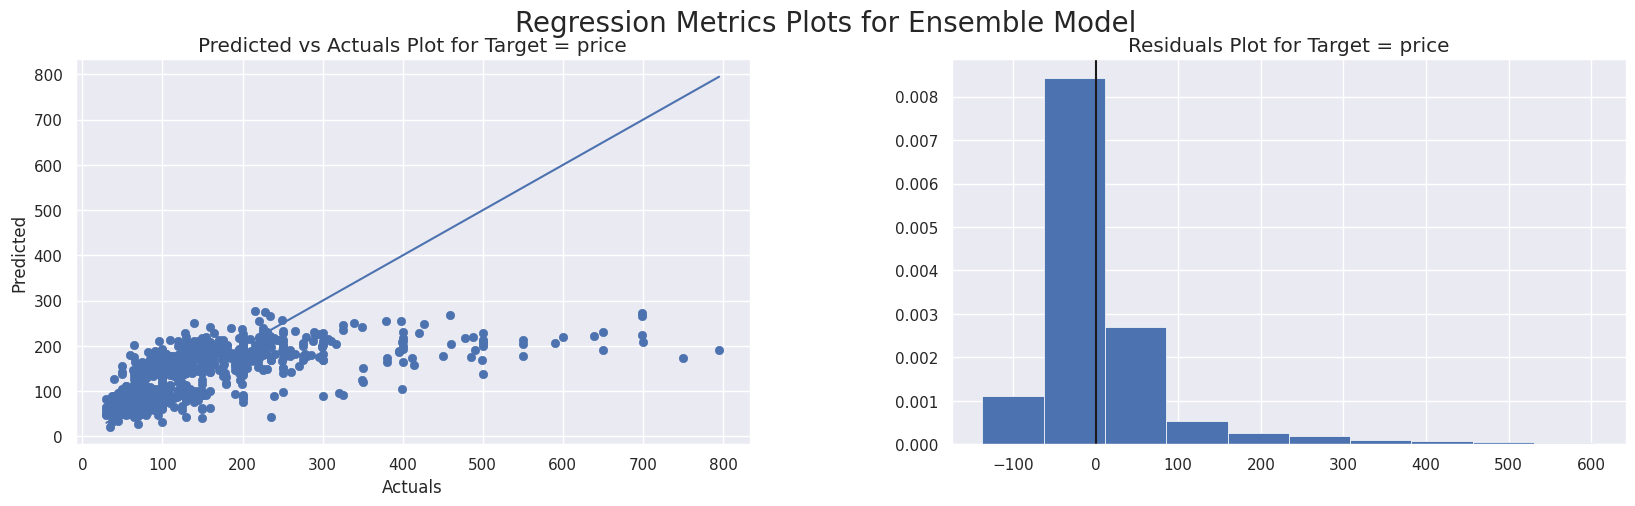

In [ ]:

from autoviml.Auto_ViML import Auto_ViML
import time

# Sample 5,000 training rows for a faster trial
train_small = train.sample(
    n=min(5000, len(train)),
    random_state=42
)

print("Training rows:", len(train_small))

start = time.time()

model, features, train_modified, test_modified = Auto_ViML(
    train_small,
    'price',
    test.drop(columns=['price']).copy(),
    '',
    hyper_param='RS',
    feature_reduction=False,
    Boosting_Flag=None,
    scoring_parameter='rmse',
    verbose=0
)

print(f"Training completed in {(time.time() - start):.1f} seconds")
print("Selected features:", features)


Training Random Forest AutoViML...
Training samples: 5000
##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (5000, 13)
    Training Set Memory Usage = 0.51 MB
Test Set Shape = (9777, 12)
    Test Set Memory Usage = 1.18 MB
Single_Label Target: ['price']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    12 Predictors classified...
    No variables removed since no ID or low-information variables found in data set
#######################################################################

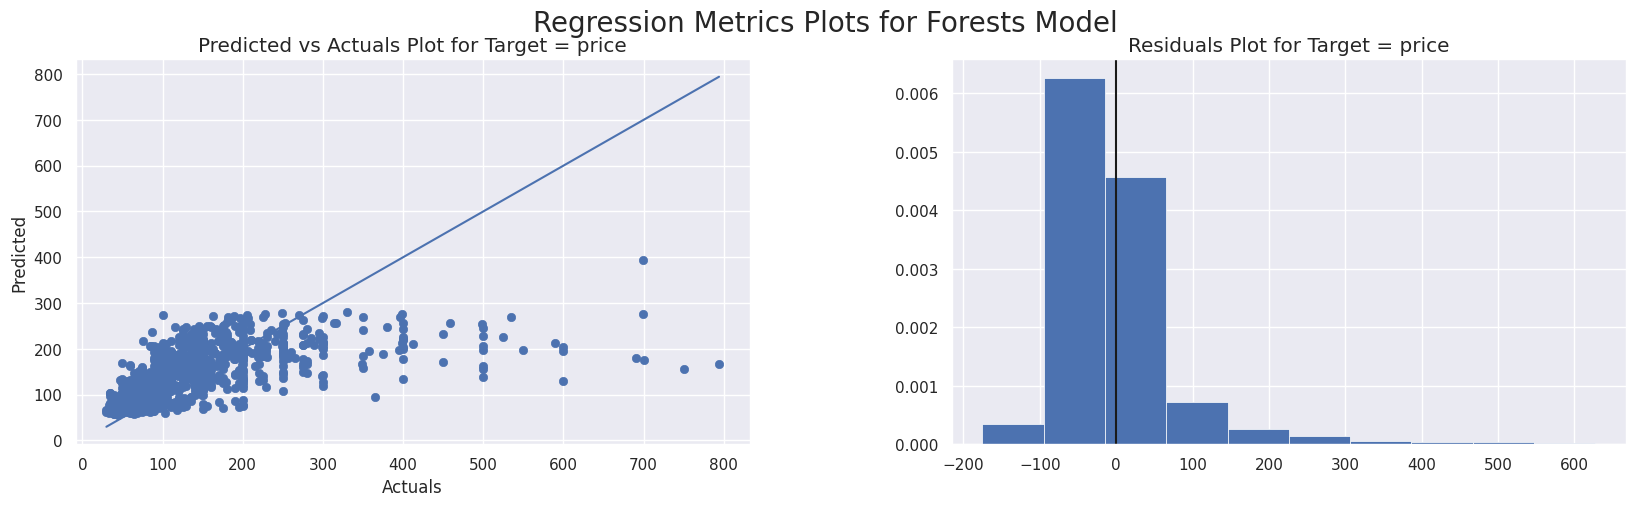

In [ ]:

from autoviml.Auto_ViML import Auto_ViML
import time

# Use the same sample size as the previous model
train_rf = train.sample(
    n=min(5000, len(train)),
    random_state=42
).copy()

# Keep the same test data
test_rf = test.drop(columns=['price']).copy()

print("Training Random Forest AutoViML...")
print("Training samples:", len(train_rf))

start = time.time()

rf_model, rf_features, rf_train, rf_test = Auto_ViML(
    train_rf,
    'price',
    test_rf,
    '',
    hyper_param='RS',
    feature_reduction=False,
    Boosting_Flag=False,
    scoring_parameter='rmse',
    verbose=0
)

print("\nRandom Forest AutoViML completed!")
print(f"Time: {time.time() - start:.1f} seconds")
print("Selected features:", rf_features)


## Part 1A — AutoViML Results and Conclusion

AutoViML was used to train and compare multiple regression models for predicting NYC Airbnb listing prices. A representative sample of 5,000 listings was used, with 12 predictive features.

Three model results were obtained:

- **Linear Model:** MAE = \$$49.73$, RMSE = \$$88.07$.
- **Linear-Run Ensemble:** MAE = \$$47.13$, RMSE = \$$80.24$.
- **Forests Model:** MAE = \$$49.31$, RMSE = \$$80.45$.

The linear-run ensemble achieved the lowest validation error, reducing RMSE by approximately 8.9% compared with the single linear model. The Forests model also performed well, achieving an RMSE of $80.45 using 251 estimators, a maximum tree depth of 7, and a minimum leaf size of 3.

Although the Forests model trained successfully, its ensemble prediction step encountered an error. The standalone Forests validation metrics were still available for evaluation.

Overall, the experiment demonstrates how automated machine learning can streamline feature processing, hyperparameter tuning, and model comparison. The results suggest that nonlinear and ensemble-based methods may improve Airbnb price predictions compared with a single linear model.

The reported metrics are from AutoViML's internal held-out validation sets rather than an independently evaluated final test set.